<a href="https://colab.research.google.com/github/FishOnFireGH/HW_WW_DataAnalysis/blob/do_main/%D0%97%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Работу выполнил: Минеев Лев Львович

Датасет на гугл диске: https://drive.google.com/drive/folders/1ei-Kjoj0MtyBsou01YEwK8M4ateAU_V3

1. Сформулировать постановку задачу, которую хочется решать в рамках курса.
  - Бизнес постановка задачи:Реализовать систему предварительной проверки исполняемых PE-файлов (.exe, .dll) на вредоносность до их запуска, используя только статические признаки (без запуска в песочнице).
  - Постановка ML-задачи:Бинарная классификация. По статическим признакам PE-файла (заголовок, секции, импортируемые DLL, вызываемые API-функции) нужно предсказать, вредоносный файл или легитимный: 1 — malware, 0 — benign. Исходная многоклассовая метка сводится к бинарной.
  - Набор данных для решения поставленной задачи:
  Ссылка: https://www.kaggle.com/datasets/joebeachcapital/windows-malwares

    Датасет «Windows Malwares» (Kaggle: joebeachcapital/windows-malwares) — академический набор «A Multi-feature Dataset for Windows PE Malware Classification» (18 551 образец, malware из MalwareBazaar, разметка через VirusTotal). Четыре CSV-файла, связанные по SHA256, каждый — отдельный набор статических признаков, извлечённых pefile:

  PE_Header.csv — 52 поля из PE-заголовка;

  PE_Section.csv — по 9 полей для 10 секций;

  DLLs_Imported.csv — бинарные признаки импортируемых DLL;

  API_Functions.csv — бинарные признаки вызываемых API-функций (~1.3 ГБ, тысячи столбцов) (Путём проб и ошибок было решено пока его не обрабатывать).

Данных достаточно для обучения и валидации: есть богатый набор статических признаков и бинарно-преобразуемая целевая метка.

2. Выбрать и обосновать метрику для измерения качества.
- Recall — основная метрика: доля выявленных вредоносных файлов среди всех malware.

- Precision — контроль ложных тревог: доля реально вредоносных среди помеченных моделью.

- F1-score — баланс Precision и Recall, удобен для сравнения моделей при дисбалансе.

- ROC-AUC — качество ранжирования файлов по степени риска по всем порогам.

- PR-AUC — более информативна, чем ROC-AUC, при сильном дисбалансе классов.

- Confusion matrix — интерпретация ошибок (TP/FP/TN/FN).

- Accuracy не используется — при дисбалансе классов она вводит в заблуждение.

Обоснование
Recall — приоритетная метрика. В задаче ИБ самая дорогая ошибка — False Negative (пропуск вредоносного файла), потому что это означает заражение рабочей станции. Поэтому модель должна выявлять как можно большую долю malware.

Precision и FPR контролируются отдельно. При огромном потоке легитимных файлов даже малый процент ложных тревог (False Positive) перегружает аналитиков SOC и раздражает пользователей, поэтому важно удерживать Precision на приемлемом уровне.

F1-score даёт сводную оценку баланса Precision и Recall и удобен для сравнения моделей между собой при дисбалансе классов.

ROC-AUC и PR-AUC измеряют качество ранжирования файлов по предсказанной вероятности malware независимо от выбранного порога. Это напрямую связано с бизнес-постановкой: служба ИБ может обрабатывать файлы в порядке убывания риска. PR-AUC предпочтительнее ROC-AUC, когда класс malware представлен не так широко, как benign, поскольку ROC-AUC в таких условиях может давать завышенную оценку.

Связь с бизнес-постановкой. Recall и Precision при выбранном пороге напрямую определяют, сколько атак система блокирует и сколько ложных тревог создаёт. ROC-AUC/PR-AUC позволяют приоритизировать входящий поток по степени риска. Финальный рабочий порог выбирается с учётом допустимого уровня FPR (например, «не более 1% ложных тревог»). Набор метрик отражает главный компромисс задачи: не пропустить угрозу, но не зашуметь ложными срабатываниями.

3. EDA:

In [ ]:
# ============================================================
# 0. МОНТИРОВАНИЕ GOOGLE DRIVE И ЗАГРУЗКА ДАННЫХ
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Программные инструменты анализа данных в задачах информационной безопасности/Задание1"
os.chdir(PROJECT_DIR)
print("Рабочая директория:", os.getcwd())
print("Файлы в папке:", os.listdir())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# загрузка датасетов
header  = pd.read_csv("PE_Header.csv")
section = pd.read_csv("PE_Section.csv")
dlls    = pd.read_csv("DLLs_Imported.csv")

# ============================================================
#  API_Functions.csv слишком большой, пока обрабатывать его не буду
# ============================================================
# API_Functions.csv большой (~1.3 ГБ) — читаем с оптимизацией типов
#cols = pd.read_csv("API_Functions.csv", nrows=1).columns.tolist()
#dtypes_dict = {col: 'int8' for col in cols}
#dtypes_dict['SHA256'] = 'str'
#dtypes_dict['Label'] = 'int8'

#print("Загрузка API_Functions.csv (с оптимизацией памяти)...")
#api = pd.read_csv("API_Functions.csv",  dtype=dtypes_dict)

print("Формы датасетов:")
print("  PE_Header:     ", header.shape)
print("  PE_Section:    ", section.shape)
print("  DLLs_Imported: ", dlls.shape)
#print("  API_Functions: ", api.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Рабочая директория: /content/drive/MyDrive/Colab Notebooks/Программные инструменты анализа данных в задачах информационной безопасности/Задание1
Файлы в папке: ['API_Functions.csv', 'PE_Header.csv', 'DLLs_Imported.csv', 'PE_Section.csv', 'Задание 1.ipynb']
Формы датасетов:
  PE_Header:      (29807, 54)
  PE_Section:     (29760, 92)
  DLLs_Imported:  (29498, 631)


In [ ]:
# ============================================================
# 1. БАЗОВЫЕ ХАРАКТЕРИСТИКИ КАЖДОГО ФАЙЛА
# ============================================================
def basic_info(name, df):
    print(f"\n=== {name} ===")
    print(f"  shape:          {df.shape}")
    print(f"  dtypes:         {df.dtypes.value_counts().to_dict()}")
    print(f"  пропуски:       {df.isna().sum().sum()}")
    print(f"  дубликаты SHA256: {df['SHA256'].duplicated().sum() if 'SHA256' in df.columns else 'нет столбца'}")

for name, df in [("PE_Header", header), ("PE_Section", section),
                 ("DLLs_Imported", dlls)]:#, ("API_Functions", api)
    basic_info(name, df)


=== PE_Header ===
  shape:          (29807, 54)
  dtypes:         {dtype('int64'): 53, dtype('O'): 1}
  пропуски:       0
  дубликаты SHA256: 0

=== PE_Section ===
  shape:          (29760, 92)
  dtypes:         {dtype('int64'): 91, dtype('O'): 1}
  пропуски:       0
  дубликаты SHA256: 0

=== DLLs_Imported ===
  shape:          (29498, 631)
  dtypes:         {dtype('int64'): 630, dtype('O'): 1}
  пропуски:       0
  дубликаты SHA256: 3


1. Мы проверили размерность (shape), типы данных (dtypes), наличие пропусков и дубликатов по хэшу SHA256. Выявили отсутствие пропусков, разное количество строк и несколько дубликатов.

In [ ]:
# ============================================================
# 2. ОБЪЕДИНЕНИЕ ДАННЫХ (INNER JOIN) И ОЧИСТКА
# ============================================================
# 1. Удаляем дубликаты по SHA256, которые мы нашли (чтобы не было размножения строк при merge)
dlls = dlls.drop_duplicates(subset=['SHA256'])
#api = api.drop_duplicates(subset=['SHA256'])

# 2. Убираем целевую переменную Type из вспомогательных таблиц,
# чтобы при объединении не появились столбцы Type_x, Type_y.
# Она нам нужна только из PE_Header.
section = section.drop(columns=['Type'], errors='ignore')
dlls = dlls.drop(columns=['Type'], errors='ignore')
#api = api.drop(columns=['Type'], errors='ignore')

# 3. Выполняем последовательное Inner Join по хэшу файла
print("Объединение данных...")
df_all = pd.merge(header, section, on='SHA256', how='inner')
df_all = pd.merge(df_all, dlls, on='SHA256', how='inner')
#df_all = pd.merge(df_all, api, on='SHA256', how='inner')

print(f"Размерность после объединения: {df_all.shape}")
print(f"Потеряно файлов (было {header.shape[0]}, стало {df_all.shape[0]}): {header.shape[0] - df_all.shape[0]}")

# Очищаем память от ненужных больше отдельных датафреймов
#import gc
#del header, section, dlls#, api
#gc.collect()

Объединение данных...
Размерность после объединения: (29492, 773)
Потеряно файлов (было 29807, стало 29492): 315


2. Удалили дубликаты, убрали дублирующийся столбец Type из вспомогательных таблиц и объединили все четыре датафрейма в один (df_all) по столбцу SHA256 с помощью how='inner', чтобы у каждого файла в выборке был полный набор признаков (заголовок, секции, DLL и API). inner join оставил только те файлы, которые есть во всех четырех таблицах. Остатки «сиротских» строк (около 300 файлов) мы отбросили ради чистоты данных.


--- Значения в столбце Type ---
Type
4    5076
1    5022
3    4955
2    4643
5    4220
6    3699
0    1877
Name: count, dtype: int64

--- Бинарная метка (доли) ---
Label_binary
1    0.9364
0    0.0636
Name: proportion, dtype: float64


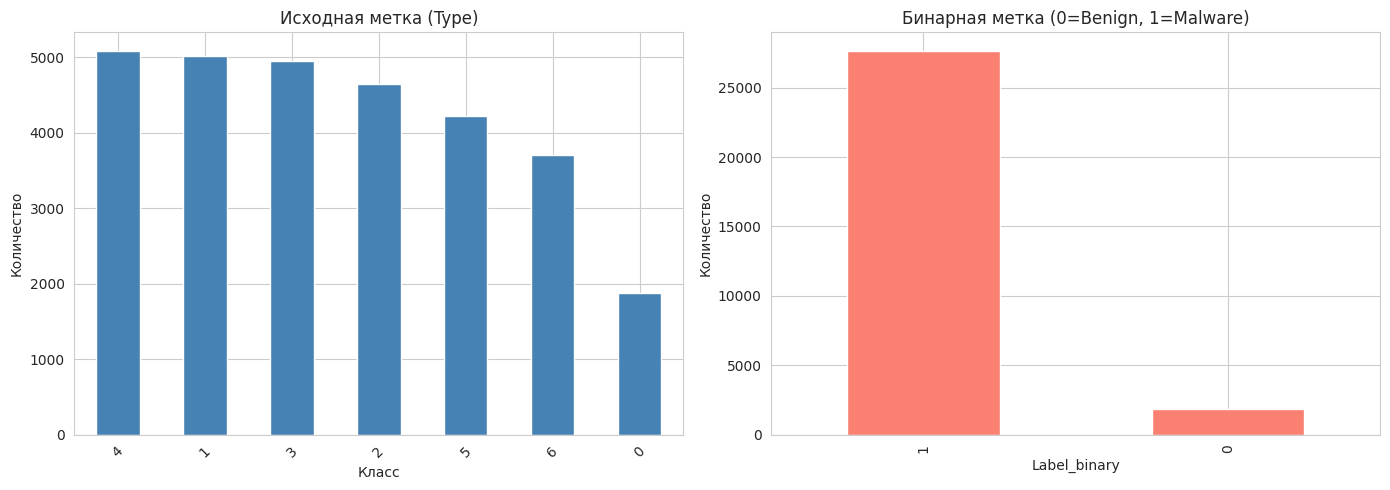

In [ ]:
# ============================================================
# 3. ЦЕЛЕВАЯ ПЕРЕМЕННАЯ И ДИСБАЛАНС КЛАССОВ
# ============================================================
# Смотрим, какие значения лежат в столбце Type
print("\n--- Значения в столбце Type ---")
print(df_all["Type"].value_counts())

# Создаем бинарную метку.
# Логика: если это 'Benign' (или 0, если там числа), то 0, иначе 1.
# Если значения текстовые:
#df_all["Label_binary"] = (df_all["Type"] != "Benign").astype(int)

# Если вдруг там числовые значения (0 = Benign, 1..6 = Malware), то код будет таким:
df_all["Label_binary"] = (df_all["Type"] != 0).astype(int)

print("\n--- Бинарная метка (доли) ---")
print(df_all["Label_binary"].value_counts(normalize=True).round(4))

# --- ВИЗУАЛИЗАЦИЯ ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Исходные классы (Type)
df_all["Type"].value_counts().plot(
    kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Исходная метка (Type)")
axes[0].set_xlabel("Класс"); axes[0].set_ylabel("Количество")
axes[0].tick_params(axis='x', rotation=45) # Поворачиваем подписи, если они длинные

# График 2: Бинарная метка
df_all["Label_binary"].value_counts().plot(
    kind="bar", ax=axes[1], color="salmon")
axes[1].set_title("Бинарная метка (0=Benign, 1=Malware)")
axes[1].set_xlabel("Label_binary"); axes[1].set_ylabel("Количество")

plt.tight_layout()
plt.show()

3. Создали бинарную метку Label_binary (0 = Benign, 1 = Malware) на основе столбца Type. Построили столбчатые диаграммы распределения классов, чтобы перевести многоклассовую задачу (определение конкретного семейства вирусов) в бинарную (вирус/не вирус). По графикам видно, что Большинство файлов вредоносные в датасетах, лишь 1877 файлов не вредоносные (из примерно 29 000)


--- describe() по числовым признакам PE_Header ---


,count,mean,std,min,25%,50%,75%,max
e_magic,29492.0,23117.00,0.00,23117.0,23117.0,23117.0,23117.0,23117.0
e_cblp,29492.0,250.46,1512.17,0.0,144.0,144.0,144.0,64110.0
e_cp,29492.0,758.15,6605.68,0.0,3.0,3.0,3.0,62388.0
e_crlc,29492.0,406.02,3652.51,0.0,0.0,0.0,0.0,63030.0
e_cparhdr,29492.0,43.35,1292.32,0.0,4.0,4.0,4.0,64913.0
...,...,...,...,...,...,...,...,...
api-ms-win-core-fibers-l1-1-0.dll,29492.0,0.00,0.01,0.0,0.0,0.0,0.0,1.0
api-ms-win-core-file-l2-1-0.dll,29492.0,0.00,0.01,0.0,0.0,0.0,0.0,1.0
api-ms-win-core-sysinfo-l1-2-0.dll,29492.0,0.00,0.01,0.0,0.0,0.0,0.0,1.0
dbgeng.dll,29492.0,0.00,0.01,0.0,0.0,0.0,0.0,1.0


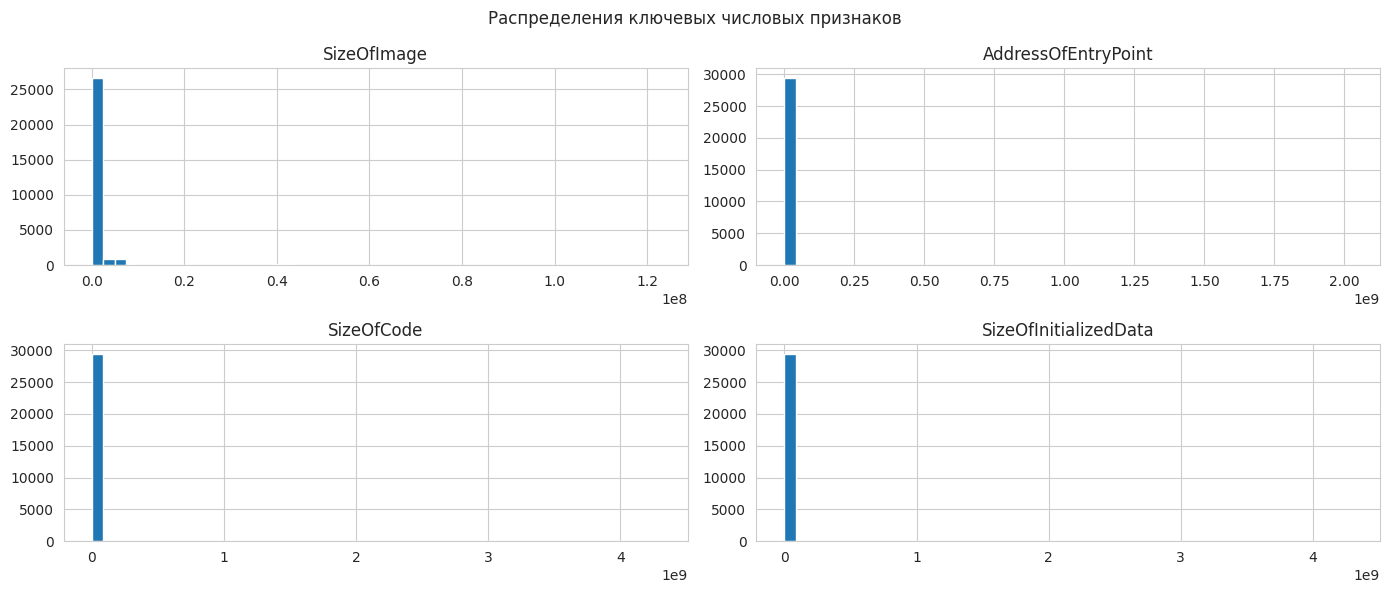

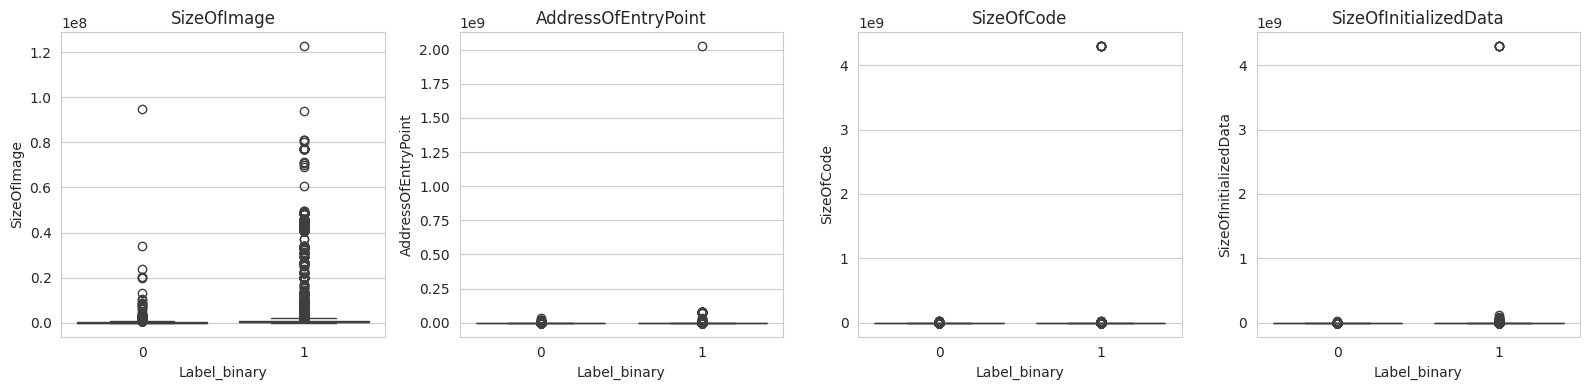

In [ ]:
# ============================================================
# 4. ЧИСЛОВЫЕ ПРИЗНАКИ PE_Header
# ============================================================
num_cols = df_all.select_dtypes(include=np.number).columns.drop(
    ["Label_binary", "Type"], errors="ignore"
)
print("\n--- describe() по числовым признакам PE_Header ---")
display(df_all[num_cols].describe().T.round(2))

# распределения ключевых признаков
key_cols = ["SizeOfImage", "AddressOfEntryPoint",
            "SizeOfCode", "SizeOfInitializedData"]
key_cols = [c for c in key_cols if c in df_all.columns]

df_all[key_cols].hist(bins=50, figsize=(14, 6))
plt.suptitle("Распределения ключевых числовых признаков")
plt.tight_layout(); plt.show()

# сравнение распределений benign vs malware
fig, axes = plt.subplots(1, len(key_cols), figsize=(4 * len(key_cols), 4))
for ax, col in zip(np.atleast_1d(axes), key_cols):
    sns.boxplot(data=df_all, x="Label_binary", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()




4. Вывели базовую статистику (describe), построили гистограммы распределения и «ящики с усами» (boxplot) для ключевых признаков (размер кода, точка входа и т.д.), разделив их по классам, чтобы  понять, как распределены признаки (есть ли выбросы, перекосы) и визуально оценить, отличаются ли легитимные файлы от вредоносных по этим параметрам.

 Распределения имеют сильный перекос вправо. Почти все экстремально большие выбросы (до 4×10^9) относятся к классу вредоносного ПО (Malware), потому что вирусы часто используют упаковщики (packers), которые искусственно раздувают размер файла, чтобы скрыть свой код от антивирусов. У чистых файлов (Benign) размеры гораздо более предсказуемые.

 Вывод для предобработки: Удалять эти выбросы нельзя — это важный признак заражения. Вместо этого на этапе ML мы применим логарифмирование (log1p), чтобы сжать масштаб чисел. Для древовидных моделей (Random Forest, XGBoost) дополнительная обработка не нужна — они отлично работают с такими данными «из коробки».

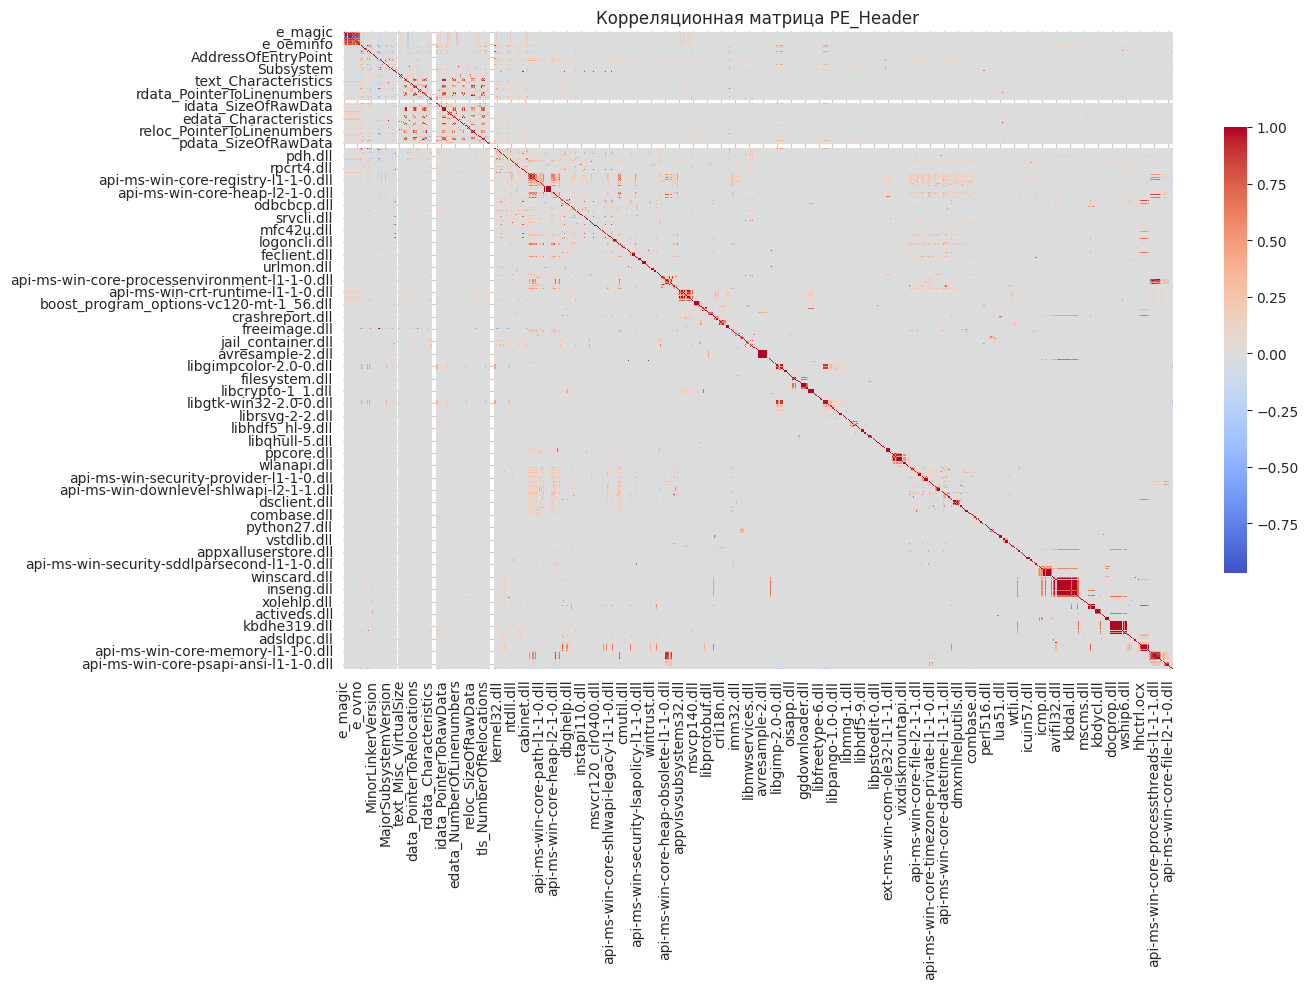


--- Топ-15 признаков по |corr| с целевой ---
Magic                       0.454
Machine                     0.454
SizeOfOptionalHeader        0.454
pdata_Characteristics       0.407
libintl-8.dll               0.301
libglib-2.0-0.dll           0.299
libgimp-2.0-0.dll           0.292
libgimpbase-2.0-0.dll       0.292
libgobject-2.0-0.dll        0.271
libgimpui-2.0-0.dll         0.270
libgtk-win32-2.0-0.dll      0.264
MinorSubsystemVersion       0.263
libgimpwidgets-2.0-0.dll    0.262
ImageBase                   0.260
Subsystem                   0.249
Name: Label_binary, dtype: float64

--- Пары с |r| > 0.9 ---
  ('e_cp', 'e_crlc', np.float64(0.945))
  ('e_cp', 'e_minalloc', np.float64(0.974))
  ('e_cp', 'e_maxalloc', np.float64(-0.97))
  ('e_cp', 'e_ss', np.float64(0.949))
  ('e_cp', 'e_csum', np.float64(0.939))
  ('e_cp', 'e_ovno', np.float64(0.933))
  ('e_crlc', 'e_minalloc', np.float64(0.965))
  ('e_crlc', 'e_maxalloc', np.float64(-0.95))
  ('e_crlc', 'e_ss', np.float64(0.913))
  ('e

In [ ]:
# ============================================================
# 5. КОРРЕЛЯЦИОННЫЙ АНАЛИЗ
# ============================================================
corr = df_all[num_cols.tolist() + ["Label_binary"]].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, square=False,
            cbar_kws={"shrink": 0.7})
plt.title("Корреляционная матрица PE_Header")
plt.tight_layout(); plt.show()

print("\n--- Топ-15 признаков по |corr| с целевой ---")
print(corr["Label_binary"].drop("Label_binary").abs()
      .sort_values(ascending=False).head(15).round(3))

# пары с высокой мультиколлинеарностью
high_corr = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        r = corr.iloc[i, j]
        if abs(r) > 0.9:
            high_corr.append((num_cols[i], num_cols[j], round(r, 3)))
print("\n--- Пары с |r| > 0.9 ---")
for pair in high_corr[:20]:
    print(" ", pair)

5. Для корреляционного анализа мы построили тепловую карту (heatmap) и вывели топ признаков, наиболее связанных с целевой переменной.

Что выявили, что нет «серебряной пули»: Максимальная корреляция признака с целевой переменной составляет всего около 0.45 (у признаков Magic, Machine, SizeOfOptionalHeader). Это значит, что нет какого-то одного признака, по которому можно сразу отличить вирус. Модели придется учитывать комбинацию множества фичей.

Связь с библиотеками (DLL): В топ-15 попали такие библиотеки, как libintl-8.dll, libglib-2.0-0.dll, libgimp.... Это говорит о том, что наличие определенных (часто специфических или open-source) библиотек может быть маркером вредоносных сборок.

Мультиколлинеарность: Обнаружены пары признаков с идеальной корреляцией 1.0 (Machine и Magic, Machine и SizeOfOptionalHeader). Также сильно (до 0.97) коррелируют признаки DOS-заголовка (e_cp, e_cminalloc, e_ss и др.).

Вывод для предобработки:

Из идеально коррелирующих троек (Machine, Magic, SizeOfOptionalHeader) нужно оставить только один признак, чтобы не дублировать информацию.

Признаки DOS-заголовка (e_...) можно удалить почти все — современные Windows-программы их не используют, они несут мало смысла и создают лишний шум.

Наличие умеренных корреляций (0.2–0.4) с целевой переменной подтверждает, что для качественного детекта нужно использовать модели, способные улавливать сложные нелинейные связи (например, Random Forest или градиентный бустинг).

In [ ]:
# ============================================================
# 6. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ
# ============================================================
cat_cols = df_all.select_dtypes(include="object").columns.drop(
    "SHA256", errors="ignore").tolist()
print("\nКатегориальные столбцы:", cat_cols)

for col in cat_cols[:5]:
    print(f"\n--- {col} (кардинальность: {df_all[col].nunique()}) ---")
    print(df_all[col].value_counts().head(10))

for col in cat_cols[:3]:
    plt.figure(figsize=(9, 4))
    top = df_all[col].value_counts().head(10).index
    sns.countplot(data=df_all[df_all[col].isin(top)],
                  x=col, hue="Label_binary")
    plt.xticks(rotation=45); plt.title(col)
    plt.tight_layout(); plt.show()


Категориальные столбцы: []


6. Это просто поиск текстовых переменных, у нас их нет, поэтому всё в порядке


--- Плотность бинарных признаков ---
DLL: столбцов 629, с density < 0.01: 603


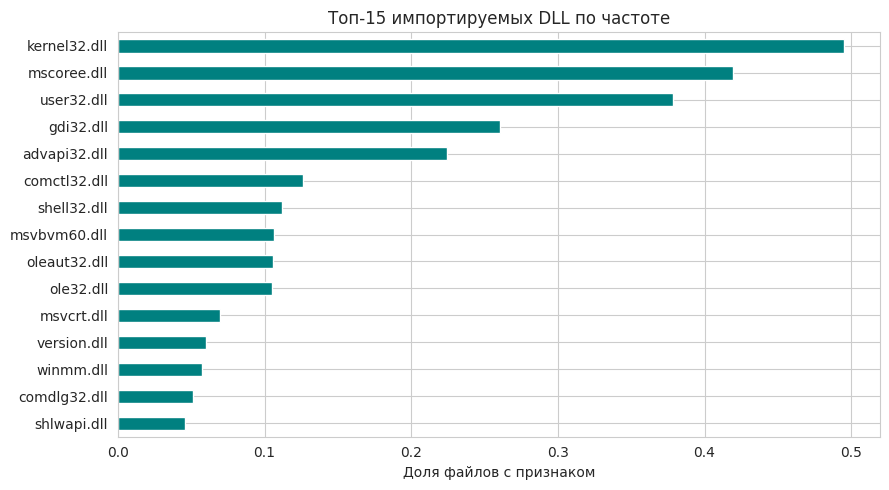

In [ ]:
# ============================================================
# 7. РАЗРЕЖЕННЫЕ БИНАРНЫЕ ПРИЗНАКИ (DLLs / API)
# ============================================================
dll_density = dlls.drop(columns=["SHA256", "Label"], errors="ignore").mean()
#api_density = api.drop(columns=["SHA256", "Label"], errors="ignore").mean()

print("\n--- Плотность бинарных признаков ---")
print(f"DLL: столбцов {len(dll_density)}, с density < 0.01: "
      f"{(dll_density < 0.01).sum()}")
#print(f"API: столбцов {len(api_density)}, с density < 0.01: "
#      f"{(api_density < 0.01).sum()}")

plt.figure(figsize=(9, 5))
dll_density.sort_values(ascending=False).head(15).plot(
    kind="barh", color="teal")
plt.title("Топ-15 импортируемых DLL по частоте")
plt.xlabel("Доля файлов с признаком"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

#plt.figure(figsize=(9, 5))
#api_density.sort_values(ascending=False).head(15).plot(
#    kind="barh", color="darkorange")
#plt.title("Топ-15 API-функций по частоте")
#plt.xlabel("Доля файлов с признаком"); plt.gca().invert_yaxis()
#plt.tight_layout(); plt.show()

7. Анализ разреженных бинарных признаков (DLLs_Imported):
Для признаков импортируемых библиотек была рассчитана их плотность (доля файлов в датасете, где встречается библиотека).

Что выявили: Обнаружена экстремальная разреженность данных. Из 629 признаков целых 603 (около 96%) встречаются менее чем в 1% файлов. Топ-15 самых частых библиотек представлен стандартными системными API Windows (kernel32.dll, user32.dll, advapi32.dll), а также mscoree.dll (.NET), что указывает на разнообразие типов программ в датасете.

Вывод для предобработки: Признаки с плотностью < 0.01 являются шумом и могут привести к переобучению модели. На этапе ML мы удалим эти 603 столбца, оставив только библиотеки, которые встречаются в данных достаточно часто. Это снизит размерность и повысит обобщающую способность модели. Оставшиеся системные библиотеки не будут являться сильными маркерами вредоносности (так как они есть и у легитимного ПО), однако их комбинации с другими признаками помогут модели.